# Titanic - Exploração inicial

Primeiro contato com os dados da competição [Titanic](https://www.kaggle.com/competitions/titanic) do Kaggle: tamanho da base, valores faltantes e as primeiras pistas sobre quem sobreviveu.

## 1. Carregando os dados

In [1]:
import pandas as pd

train = pd.read_csv("../data/train.csv")

In [2]:
# DataFrame (A_{ij})
train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
# (i linhas, j colunas)
train.shape

(891, 12)

A base de treino tem **891 passageiros** e **12 colunas**.

In [4]:
# Tipos das colunas e quantos valores não faltam
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Valores faltantes

In [5]:
# Quantidade de valores faltantes em cada coluna
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
# Mesma informação em porcentagem
(train.isnull().mean() * 100).round(1)

PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.9
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.1
Embarked        0.2
dtype: float64

Três colunas têm valores faltando:

- **Age**: 177 faltantes (19,9%). Dá para preencher com uma estimativa (ex.: mediana por grupo).
- **Cabin**: 687 faltantes (77,1%). Quase vazia; talvez seja mais útil saber apenas *se* o passageiro tinha cabine registrada.
- **Embarked**: 2 faltantes. Fácil de preencher com o porto mais comum.

Esses tratamentos serão feitos na etapa de limpeza.

## 3. Quem sobreviveu?

In [7]:
# Taxa geral de sobrevivência
train['Survived'].mean()

np.float64(0.3838383838383838)

Apenas **38,4%** dos passageiros sobreviveram.

### Por sexo

In [8]:
# Contagem de homens e mulheres
train['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [9]:
# Contagem de sobreviventes por sexo
train.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [10]:
# Taxa de sobrevivência por sexo
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Mulheres sobreviveram muito mais: **74,2%** contra **18,9%** dos homens. "Mulheres e crianças primeiro".

### Por classe

In [11]:
# Taxa de sobrevivência por classe (1 = primeira, 3 = terceira)
train.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

A classe também pesou: **63,0%** na 1ª classe, **47,3%** na 2ª e só **24,2%** na 3ª. Passageiros mais ricos estavam em cabines mais próximas dos botes salva-vidas.

**Conclusão:** sexo e classe são fortes candidatos a variáveis importantes no modelo, confirmando os palpites iniciais.

## 4. Gráficos

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

### Sobrevivência por sexo

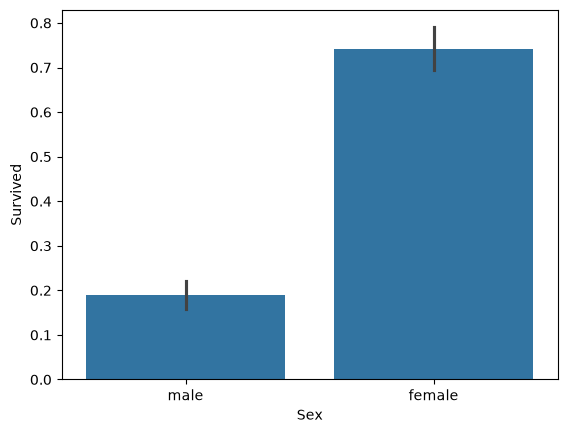

In [13]:
# Gráfico da taxa de sobrevivência por sexo
sns.barplot(data=train, x='Sex', y='Survived')
plt.show()

De fato, a taxa de sobrevivência das mulheres foi bem maior que a dos homens.

### Sobrevivência por classe

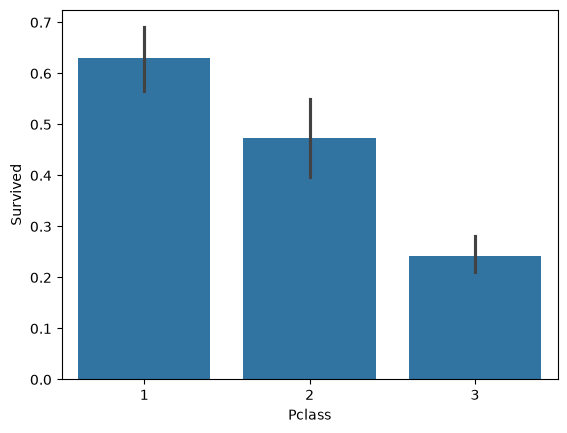

In [14]:
# Gráfico da taxa de sobrevivência por classe
sns.barplot(data=train, x='Pclass', y='Survived')
plt.show()

A taxa de sobrevivência cai a cada classe: a 1ª classe foi a que mais sobreviveu e a 3ª, a que menos.

### Idade

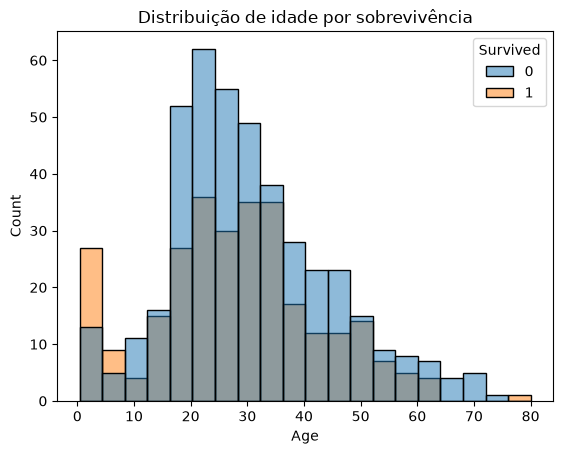

In [15]:
# Distribuição das idades, separando quem sobreviveu (1) de quem não sobreviveu (0)
sns.histplot(data=train, x='Age', hue='Survived')
plt.title('Distribuição de idade por sobrevivência')
plt.savefig('../reports/figures/idade_sobrevivencia.png', dpi=150, bbox_inches='tight')
plt.show()

Na faixa de 0 a 5 anos, a barra de sobreviventes é maior que a de mortos: cerca de **70%** das crianças pequenas sobreviveram, bem acima da média geral de 38%. Entre jovens adultos (20 a 30 anos) acontece o contrário, com muito mais mortes que sobrevivências. A partir de uns 10 anos, a idade sozinha não faz tanta diferença.

### Tarifa por classe

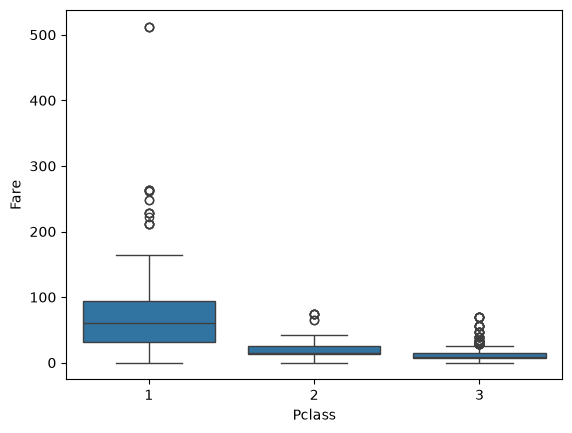

In [16]:
# Distribuição da tarifa (Fare) em cada classe
sns.boxplot(data=train, x='Pclass', y='Fare')
plt.show()

A 1ª classe pagou muito mais: a tarifa mediana foi de cerca de **60**, contra **14** na 2ª e **8** na 3ª, ou seja, umas 7 vezes mais que a 3ª classe. Há valores muito fora do padrão: 3 passageiros da 1ª classe pagaram **512**, bem acima de todo o resto.

### Classe e sexo juntos (desafio)

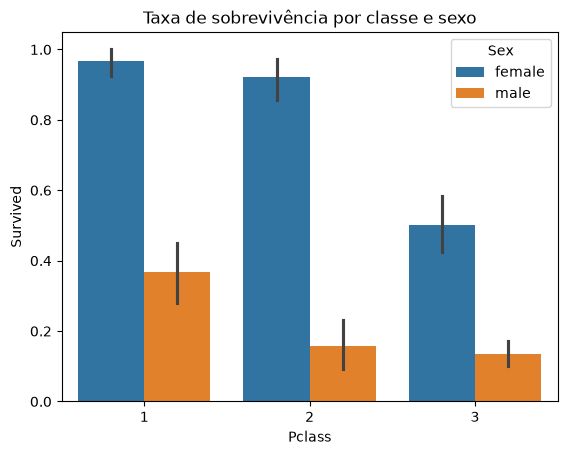

In [17]:
# Taxa de sobrevivência por classe, separando homens e mulheres
sns.barplot(data=train, x='Pclass', y='Survived', hue='Sex')
plt.title('Taxa de sobrevivência por classe e sexo')
plt.savefig('../reports/figures/sobrevivencia_classe_sexo.png', dpi=150, bbox_inches='tight')
plt.show()

Em todas as classes as mulheres sobreviveram mais que os homens. Uma mulher da 3ª classe (**50%**) teve mais chance que um homem da 1ª (**37%**). Mesmo assim, a classe pesa: na 1ª e na 2ª quase todas as mulheres sobreviveram (97% e 92%), enquanto na 3ª só metade.

**Conclusão:** sexo é a variável mais forte, a classe vem em seguida, e a idade importa principalmente para crianças pequenas.